In [0]:
from pyspark.sql import functions as F


df = spark.table("workspace.default.mall_customers_clean")
df.printSchema()
print("Rows:", df.count())
display(df.limit(5))

root
 |-- customer_id: integer (nullable = true)
 |-- gender: string (nullable = true)
 |-- age: integer (nullable = true)
 |-- annual_income_k: integer (nullable = true)
 |-- spending_score: integer (nullable = true)
 |-- age_group: string (nullable = true)
 |-- spending_category: string (nullable = true)
 |-- income_band: string (nullable = true)

Rows: 200


customer_id,gender,age,annual_income_k,spending_score,age_group,spending_category,income_band
1,Male,19,15,39,Teenager,Low Spender,Low Income
2,Male,21,15,81,Young Adult,High Spender,Low Income
3,Female,20,16,6,Teenager,Low Spender,Low Income
4,Female,23,16,77,Young Adult,High Spender,Low Income
5,Female,31,17,40,Young Adult,Medium Spender,Low Income


In [0]:
%pip install seaborn

Looking in indexes: [REDACTED]
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


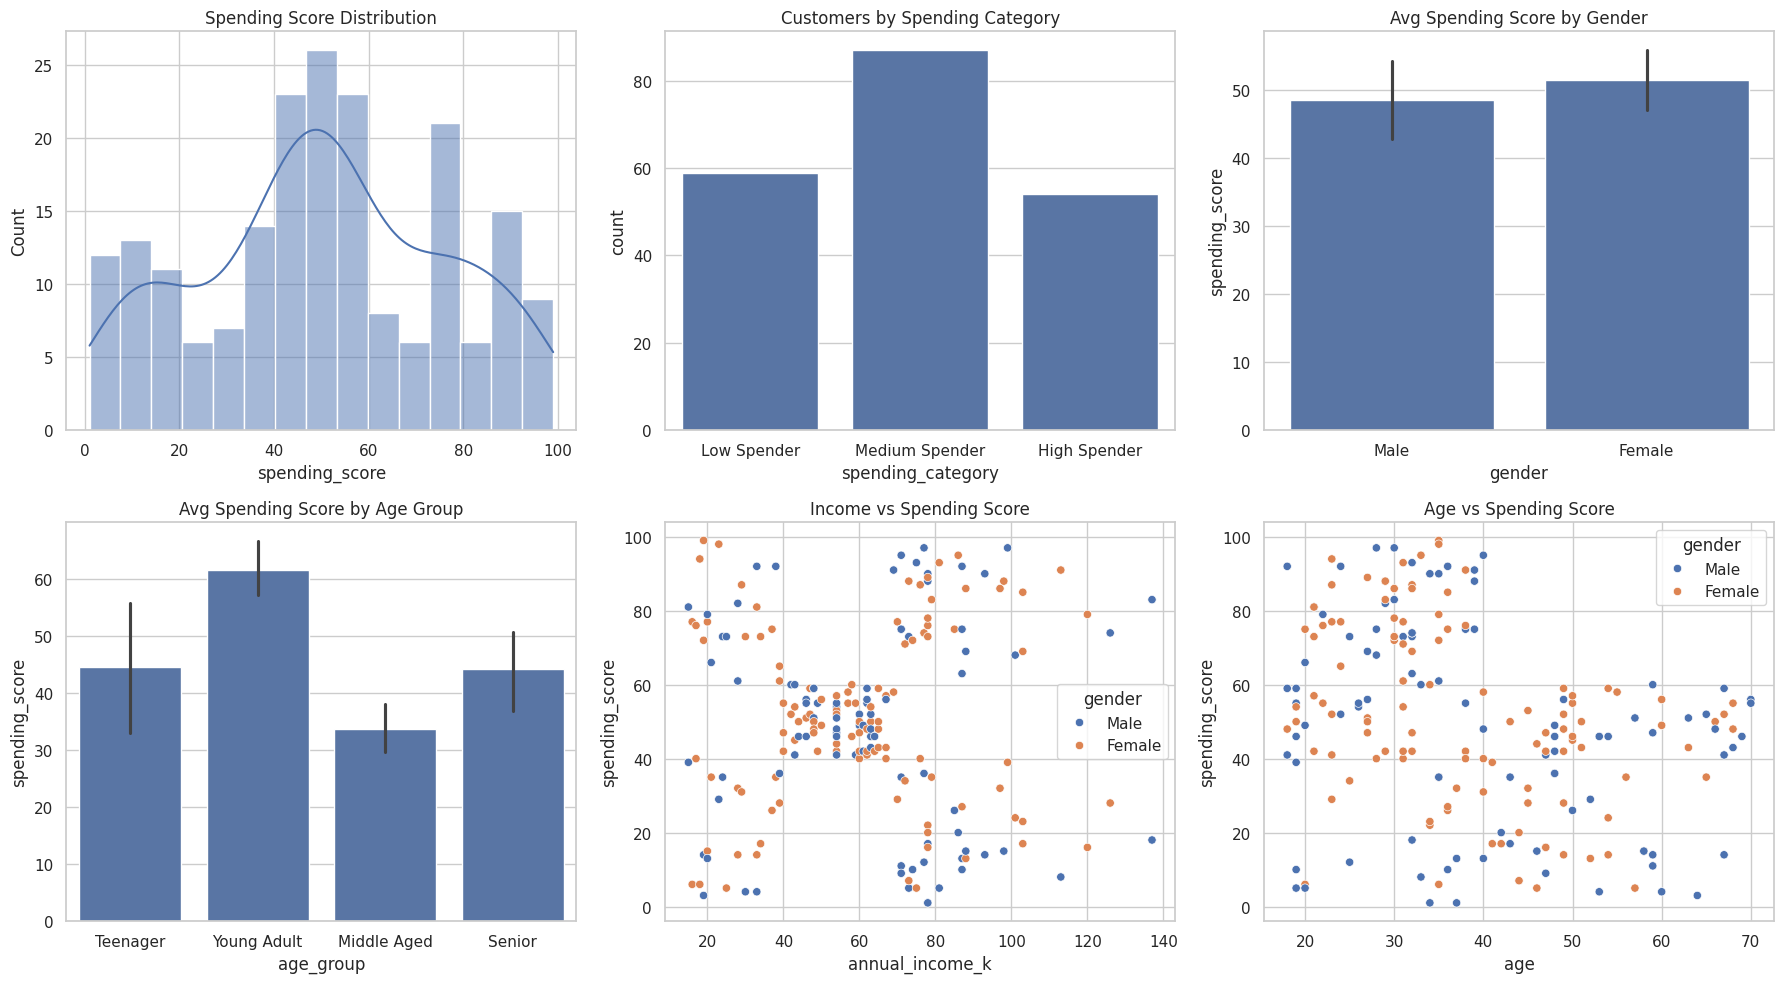

In [0]:
import matplotlib.pyplot as plt
import seaborn as sns

pdf = df.toPandas()          
sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(2, 3, figsize=(18, 10))

sns.histplot(pdf["spending_score"], bins=15, kde=True, ax=ax[0, 0])
ax[0, 0].set_title("Spending Score Distribution")

sns.countplot(data=pdf, x="spending_category",
              order=["Low Spender", "Medium Spender", "High Spender"], ax=ax[0, 1])
ax[0, 1].set_title("Customers by Spending Category")

sns.barplot(data=pdf, x="gender", y="spending_score", ax=ax[0, 2])
ax[0, 2].set_title("Avg Spending Score by Gender")

sns.barplot(data=pdf, x="age_group", y="spending_score",
            order=["Teenager", "Young Adult", "Middle Aged", "Senior"], ax=ax[1, 0])
ax[1, 0].set_title("Avg Spending Score by Age Group")

sns.scatterplot(data=pdf, x="annual_income_k", y="spending_score", hue="gender", ax=ax[1, 1])
ax[1, 1].set_title("Income vs Spending Score")

sns.scatterplot(data=pdf, x="age", y="spending_score", hue="gender", ax=ax[1, 2])
ax[1, 2].set_title("Age vs Spending Score")

plt.tight_layout()
plt.show()

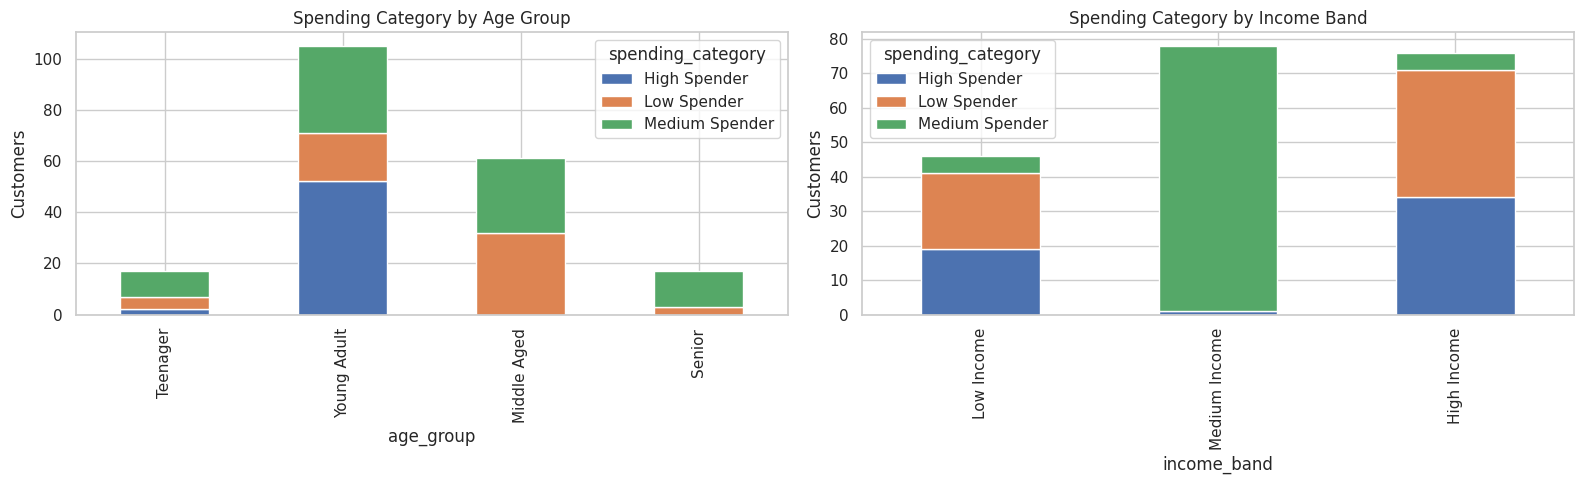

In [0]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5))

pd_age = pdf.groupby(["age_group", "spending_category"]).size().unstack(fill_value=0)
pd_age = pd_age.reindex(["Teenager", "Young Adult", "Middle Aged", "Senior"])
pd_age.plot(kind="bar", stacked=True, ax=ax[0])
ax[0].set_title("Spending Category by Age Group"); ax[0].set_ylabel("Customers")

pd_inc = pdf.groupby(["income_band", "spending_category"]).size().unstack(fill_value=0)
pd_inc = pd_inc.reindex(["Low Income", "Medium Income", "High Income"])
pd_inc.plot(kind="bar", stacked=True, ax=ax[1])
ax[1].set_title("Spending Category by Income Band"); ax[1].set_ylabel("Customers")

plt.tight_layout()
plt.show()